## mlpi26_Lect12_nbsup2.ipynb

# Reinforcement learning for robotics: from Bellman to PPO on a quadrotor

**Running example — teaching a quadrotor to hover.** One plant carries the whole lecture, at three
levels of difficulty: a 1-D altitude-hold problem small enough for a lookup table, then a planar
quadrotor (6 states, 2 rotors) controlled first with *discrete* thrust levels (DQN) and then with
*continuous* rotor commands (PPO, SAC). We finish with the step every real deployment needs:
making the policy survive a quadrotor that is not the one in the simulator.

### Learning objectives
By the end you should be able to

1. write a robot control task as a Markov decision process — state, action, reward, termination;
2. explain the Bellman optimality equation and solve a small MDP by value iteration;
3. implement tabular Q-learning and say why it cannot scale to a real vehicle;
4. explain the two tricks that make deep Q-learning stable (replay buffer, target network);
5. derive the policy-gradient idea and explain what PPO's clipped objective protects against;
6. compare on-policy (PPO) and off-policy (SAC) learning in samples *and* in compute;
7. use domain randomisation to make a simulated policy robust to mass and motor-lag errors.

### Prerequisites
Python, NumPy, basic PyTorch (`nn.Module`, autograd, an optimiser loop), and Newton's second law.
No RL background is assumed.

| part | method | what it teaches |
|---|---|---|
| 1-D altitude hold | value iteration, Q-learning | Bellman equation; learning without a model |
| planar quad, 9 discrete actions | DQN | function approximation, replay, target network |
| planar quad, continuous thrust | PPO | policy gradients, actor-critic, clipping |
| planar quad, continuous thrust | SAC | off-policy actor-critic, sample efficiency |
| planar quad, randomised physics | PPO + domain randomisation | sim-to-real |

Everything is simulated, seeded and runs on a CPU with no downloads (≈ 6–8 minutes in total).

In [1]:
import sys, time, json
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt

torch.set_num_threads(2)
print("python", sys.version.split()[0], "| numpy", np.__version__, "| torch", torch.__version__,
      "| matplotlib", matplotlib.__version__)

SURF, INK2, GRID = "#fcfcfb", "#52514e", "#e1e0d9"
BLUE, ORANGE, AQUA, YELLOW, RED, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948", "#4a3aa7"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.grid": True,
                     "grid.color": GRID, "axes.spines.top": False, "axes.spines.right": False,
                     "legend.frameon": False, "figure.dpi": 110})
G = 9.81

python 3.13.17 | numpy 2.5.3 | torch 2.14.1+cu130 | matplotlib 3.11.2


## 1. The robot as a Markov decision process

Reinforcement learning (RL) is learning to act from **trial and evaluation** rather than from labelled
examples. Nobody tells the quadrotor the correct thrust at each instant; it tries something, the world
responds, and a scalar **reward** says how good that was. Formally the task is a *Markov decision
process* (MDP) $(\mathcal S, \mathcal A, p, r, \gamma)$:

| symbol | meaning | for the hovering quadrotor |
|---|---|---|
| $s_t \in \mathcal S$ | state | position error, attitude, their rates |
| $a_t \in \mathcal A$ | action | rotor thrust commands |
| $p(s_{t+1}\mid s_t,a_t)$ | dynamics | Newton–Euler equations, integrated at 50 Hz |
| $r(s_t,a_t)$ | reward | large when close to the target, upright and calm |
| $\gamma \in [0,1)$ | discount | how far ahead the controller cares (0.99 ≈ 2 s horizon at 50 Hz) |

The agent's **policy** $\pi(a\mid s)$ maps states to actions. Its goal is to maximise the expected
**discounted return** $G_t = \sum_{k\ge 0}\gamma^k r_{t+k}$. Two functions measure how good things are:

$$V^\pi(s) = \mathbb E_\pi[G_t \mid s_t=s], \qquad Q^\pi(s,a) = \mathbb E_\pi[G_t\mid s_t=s,\,a_t=a].$$

*Markov* means the state contains everything needed to predict the future. Position alone is not a
Markov state for a quadrotor — two vehicles at the same place can be climbing and falling. Choosing
the state is the first engineering decision, and it is yours, not the algorithm's.

### 1.1 The smallest version: altitude hold

Keep only the vertical axis. The state is altitude $z$ and climb rate $\dot z$; the action is one of three
collective-thrust levels, $0.55\,mg$, $1.0\,mg$ or $1.45\,mg$; the control step is 0.1 s. The reward
penalises squared altitude error and speed, and hitting the floor or ceiling ends the episode with $-20$.
We discretise $(z, \dot z)$ into a $41\times 41$ grid so that $Q$ fits in a table.

In [2]:
class AltitudeHold:
    '''Vertical axis only. Collective thrust is one of three levels (x m*g).'''
    Z_TARGET = 1.0
    THRUST = np.array([0.55, 1.00, 1.45])          # x hover thrust
    DT = 0.1
    NZ, NV = 41, 41
    Z_EDGES = np.linspace(0.0, 2.0, NZ + 1)
    V_EDGES = np.linspace(-2.0, 2.0, NV + 1)
    Z_C = 0.5 * (Z_EDGES[1:] + Z_EDGES[:-1])
    V_C = 0.5 * (V_EDGES[1:] + V_EDGES[:-1])

    @classmethod
    def step_cont(cls, z, v, a):
        acc = G * (cls.THRUST[a] - 1.0) - 0.15 * v
        v2 = v + acc * cls.DT
        z2 = z + 0.5 * (v + v2) * cls.DT
        crash = (z2 <= 0.0) | (z2 >= 2.0)
        r = -((z2 - cls.Z_TARGET) ** 2) - 0.05 * v2 ** 2
        r = np.where(crash, -20.0, r)
        return z2, np.clip(v2, -1.999, 1.999), r, crash

    @classmethod
    def idx(cls, z, v):
        iz = np.clip(np.digitize(z, cls.Z_EDGES) - 1, 0, cls.NZ - 1)
        iv = np.clip(np.digitize(v, cls.V_EDGES) - 1, 0, cls.NV - 1)
        return iz * cls.NV + iv

    @classmethod
    def model(cls):
        '''Deterministic tabular model from cell centres: next state index, reward, done.'''
        Zc, Vc = np.meshgrid(cls.Z_C, cls.V_C, indexing="ij")
        Zc, Vc = Zc.ravel(), Vc.ravel()
        S = Zc.size
        P = np.zeros((S, 3), int); R = np.zeros((S, 3)); D = np.zeros((S, 3), bool)
        for a in range(3):
            z2, v2, r, c = cls.step_cont(Zc, Vc, np.full(S, a))
            P[:, a], R[:, a], D[:, a] = cls.idx(z2, v2), r, c
        return P, R, D


P, Rw, D = AltitudeHold.model()
print("tabular MDP:", P.shape[0], "states x", P.shape[1], "actions")

tabular MDP: 1681 states x 3 actions


## 2. Bellman's equation and value iteration

The optimal value satisfies a recursive consistency condition — the **Bellman optimality equation**:

$$V^*(s) = \max_a \Big[\, r(s,a) + \gamma \, \mathbb E\, V^*(s') \Big], \qquad
Q^*(s,a) = r(s,a) + \gamma\, \mathbb E \max_{a'} Q^*(s',a').$$

"The value of being here is the best you can get now plus the discounted value of where that leaves you."
If we *know* the model $p$ and $r$, we can turn the equation into an update and iterate it until it stops
changing — **value iteration**. The update is a $\gamma$-contraction, so it converges from any start.
Once $V^*$ is known the optimal policy is greedy: $\pi^*(s) = \arg\max_a Q^*(s,a)$.

In [3]:
def value_iteration(P, R, D, gamma=0.97, tol=1e-6, max_iter=2000):
    S = P.shape[0]
    V = np.zeros(S); deltas = []
    for it in range(max_iter):
        Q = R + gamma * np.where(D, 0.0, V[P])
        V2 = Q.max(1)
        d = np.abs(V2 - V).max(); deltas.append(d); V = V2
        if d < tol:
            break
    return V, Q.argmax(1), Q, np.array(deltas)


def eval_altitude_policy(pi, n=200, steps=80, seed=123, gamma=0.97):
    rng = np.random.default_rng(seed)
    z = rng.uniform(0.2, 1.8, n); v = rng.uniform(-1.0, 1.0, n)
    alive = np.ones(n, bool); G_ = np.zeros(n); disc = 1.0
    for t in range(steps):
        a = pi[AltitudeHold.idx(z, v)]
        z, v, r, c = AltitudeHold.step_cont(z, v, a)
        G_ += disc * r * alive; disc *= gamma
        alive &= ~c
        z = np.where(alive, z, 1.0); v = np.where(alive, v, 0.0)
    return float(G_.mean())


V, pi_vi, Qvi, deltas = value_iteration(P, Rw, D)
print(f"converged in {len(deltas)} sweeps (max change {deltas[-1]:.1e})")
print(f"mean discounted return, optimal policy : {eval_altitude_policy(pi_vi):7.2f}")
print(f"mean discounted return, always 'hover' : {eval_altitude_policy(np.ones_like(pi_vi)):7.2f}")

converged in 209 sweeps (max change 9.8e-07)
mean discounted return, optimal policy :   -0.90
mean discounted return, always 'hover' :  -14.69


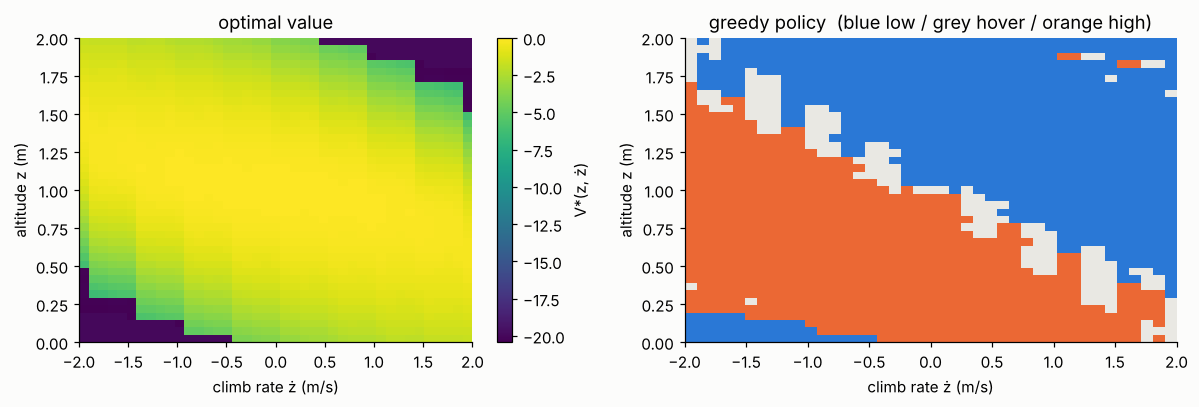

In [4]:
ext = [-2, 2, 0, 2]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
im = axs[0].imshow(V.reshape(41, 41), origin="lower", extent=ext, aspect="auto", cmap="viridis")
fig.colorbar(im, ax=axs[0], label="V*(z, ż)")
axs[1].imshow(pi_vi.reshape(41, 41), origin="lower", extent=ext, aspect="auto",
              cmap=matplotlib.colors.ListedColormap([BLUE, "#e9e8e3", ORANGE]), vmin=0, vmax=2)
axs[0].set_title("optimal value"); axs[1].set_title("greedy policy  (blue low / grey hover / orange high)")
for a in axs:
    a.set_xlabel("climb rate ż (m/s)"); a.set_ylabel("altitude z (m)"); a.grid(False)
plt.tight_layout(); plt.show()

**Read the policy map like a control engineer.** The boundary between "high thrust" and "low thrust"
is not the horizontal line $z = 1$; it is tilted. A vehicle below the target but already climbing fast
is told to cut thrust *before* it arrives. That is the switching curve of a bang–bang (time-optimal)
controller, and value iteration found it with no control theory — only the model and the reward.

Notice also that "always hover" scores -14.7 against -0.90 for the optimal policy: with only
light drag, a vehicle that starts with a velocity keeps it and leaves the safe band.

## 3. Learning without a model: Q-learning

Real robots do not hand us $p(s'\mid s,a)$. **Temporal-difference learning** replaces the expectation
in Bellman's equation with a single sampled transition $(s,a,r,s')$:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\big[\underbrace{r + \gamma \max_{a'} Q(s',a')}_{\text{TD target}} - Q(s,a)\big].$$

Q-learning is **off-policy**: the target uses the greedy $\max$, whatever action the behaviour policy
actually took next, so we can explore freely and still learn about the greedy policy. Exploration here
is **ε-greedy** — a random action with probability ε, annealed from 1.0 to 0.05.

Below, the agent never sees `AltitudeHold.model()`. It flies the *continuous* simulator and only
bins the state to index its table.

In [5]:
def q_learning(episodes=3000, alpha=0.2, gamma=0.97, eps0=1.0, eps1=0.05,
               steps=80, seed=0, Q_opt=None, eval_every=100):
    '''Tabular Q-learning on the *continuous* altitude simulator, states binned.'''
    rng = np.random.default_rng(seed)
    env = AltitudeHold
    S = env.NZ * env.NV
    Q = np.zeros((S, 3)); curve = []
    for ep in range(episodes):
        eps = eps1 + (eps0 - eps1) * max(0.0, 1 - ep / (0.6 * episodes))
        z, v = rng.uniform(0.2, 1.8), rng.uniform(-1.0, 1.0)
        for t in range(steps):
            s = env.idx(z, v)
            a = rng.integers(3) if rng.random() < eps else int(Q[s].argmax())
            z, v, r, c = env.step_cont(np.array(z), np.array(v), np.array(a))
            z, v, r, c = float(z), float(v), float(r), bool(c)
            s2 = env.idx(z, v)
            target = r if c else r + gamma * Q[s2].max()
            Q[s, a] += alpha * (target - Q[s, a])
            if c:
                break
        if (ep + 1) % eval_every == 0:
            curve.append((ep + 1, eval_altitude_policy(Q.argmax(1))))
    return Q, np.array(curve)


t0 = time.time()
Qtab, qcurve = q_learning(episodes=3000, seed=0)
print(f"{time.time() - t0:.1f} s")
for ep, ret in qcurve[::5]:
    print(f"episode {int(ep):5d}: greedy-policy return {ret:7.2f}")
print(f"final Q-learning return {eval_altitude_policy(Qtab.argmax(1)):.2f}   (value iteration {eval_altitude_policy(pi_vi):.2f})")

9.6 s
episode   100: greedy-policy return  -16.42
episode   600: greedy-policy return   -5.59
episode  1100: greedy-policy return   -3.67
episode  1600: greedy-policy return   -3.99
episode  2100: greedy-policy return   -3.18
episode  2600: greedy-policy return   -4.24
final Q-learning return -3.17   (value iteration -0.90)


Q-learning climbs from -14.7-level performance to -3.17, but does not reach the model-based
optimum of -0.90. Two reasons, both general: some cells are rarely visited, and **binning a
continuous state breaks the Markov property** — two states in one cell behave differently, and the
table must average them.

### 3.1 The curse of dimensionality

The same 41 bins per dimension on the planar quadrotor's 6-D state give $41^6 ≈ 4.75e+09$ cells; with 9
actions in float32 that is about **171 GB** of table, almost none of which would ever be visited. A full
3-D quadrotor has 12 states. The fix is to *approximate* $Q$ (or the policy) with a function that
generalises between nearby states — a neural network.

In [6]:
for name, d in (("1-D altitude", 2), ("planar quad", 6), ("3-D quad", 12)):
    cells = 41 ** d
    print(f"{name:13s} {d:2d} states -> {cells:.2e} cells, {cells * 9 * 4 / 1e9:.3g} GB of Q-table")

1-D altitude   2 states -> 1.68e+03 cells, 6.05e-05 GB of Q-table
planar quad    6 states -> 4.75e+09 cells, 171 GB of Q-table
3-D quad      12 states -> 2.26e+19 cells, 8.12e+11 GB of Q-table


## 4. The planar quadrotor

Now the real plant. Two rotors at arm length $\ell$ produce thrusts $T_1, T_2$; the body has mass $m$ and
pitch inertia $I$:

$$\ddot x = -\frac{T_1+T_2}{m}\sin\theta - c\,\dot x,\qquad
\ddot z = \frac{T_1+T_2}{m}\cos\theta - g - c\,\dot z,\qquad
\ddot\theta = \frac{\ell\,(T_2-T_1)}{I}.$$

| design choice | value | why |
|---|---|---|
| parameters | $m$ = 0.80 kg, $\ell$ = 0.17 m, $I$ = 0.006 kg m², thrust-to-weight 2 | a small 250-class quad |
| action | $u_i\in[-1,1]$, $T_i = T_\text{hover}(1+u_i)$ | $u=0$ is hover; the network output is well scaled |
| observation | $e_x, e_z, \sin\theta, \cos\theta, \dot x, \dot z, \dot\theta/4$, previous $u$ | angles as sin/cos avoid the wrap at ±π |
| reward | $1 - \|e\| - 0.2|\theta| - 0.05\|v\| - 0.02|\dot\theta| - 0.05\|\Delta u\|$ | + alive bonus, smoothness penalty |
| termination | ground, $|x|>2.5$ m, $|\theta|>1.4$ rad | a crash ends the reward stream |
| time limit | 250 steps = 5 s | a *truncation*, not a terminal state (see §5) |

The simulator steps $N$ quadrotors at once with NumPy, which is what makes training on a CPU practical.
Motor lag (a first-order time constant) and parameter randomisation are built in for §9.

In [7]:
NOMINAL = dict(mass=0.80, arm=0.17, inertia=0.0060, motor=1.0, lag=0.0, drag=0.10)


class PlanarQuad:
    '''Planar quadrotor, N copies stepped together.

    state  : x, z, theta, vx, vz, omega  (target hover point at x=0, z=1.5)
    action : normalised rotor commands u in [-1, 1]^2,  T_i = T_hover * (1 + u_i)
             (u = 0 is hover, u = +1 is 2 x hover thrust = thrust-to-weight 2)
    obs    : [ex, ez, sin th, cos th, vx, vz, omega/4, u_prev(2)]  (9-D)
    '''
    DT = 0.02
    T_MAX_STEPS = 250                      # 5 s at 50 Hz
    Z_T = 1.5

    def __init__(self, n=1, seed=0, randomize=False, params=None, obs_noise=0.0):
        self.n, self.rng, self.randomize = n, np.random.default_rng(seed), randomize
        self.fixed = dict(NOMINAL, **(params or {}))
        self.obs_noise = obs_noise
        self.p = {k: np.full(n, v, float) for k, v in self.fixed.items()}
        self.s = np.zeros((n, 6)); self.T = np.zeros((n, 2)); self.u_prev = np.zeros((n, 2))
        self.t = np.zeros(n, int)

    # -- parameters ---------------------------------------------------------
    def _sample_params(self, idx):
        k, r = len(idx), self.rng
        for key, v in self.fixed.items():
            self.p[key][idx] = v
        if self.randomize:
            self.p["mass"][idx] = NOMINAL["mass"] * r.uniform(0.75, 1.35, k)
            self.p["inertia"][idx] = NOMINAL["inertia"] * r.uniform(0.75, 1.35, k)
            self.p["motor"][idx] = r.uniform(0.80, 1.10, k)
            self.p["lag"][idx] = r.uniform(0.0, 0.08, k)

    def reset_idx(self, idx):
        k, r = len(idx), self.rng
        if k == 0:
            return
        self._sample_params(idx)
        self.s[idx, 0] = r.uniform(-1.0, 1.0, k)
        self.s[idx, 1] = self.Z_T + r.uniform(-0.8, 0.8, k)
        self.s[idx, 2] = r.uniform(-0.4, 0.4, k)
        self.s[idx, 3:5] = r.uniform(-0.5, 0.5, (k, 2))
        self.s[idx, 5] = r.uniform(-1.0, 1.0, k)
        th = NOMINAL["mass"] * G / 2
        self.T[idx] = th * self.p["motor"][idx, None]
        self.u_prev[idx] = 0.0
        self.t[idx] = 0

    def reset(self):
        self.reset_idx(np.arange(self.n))
        return self.obs()

    def set_state(self, s):
        self.s[:] = s; self.u_prev[:] = 0; self.t[:] = 0
        self.T[:] = NOMINAL["mass"] * G / 2 * self.p["motor"][:, None]
        return self.obs()

    def obs(self):
        x, z, th, vx, vz, om = self.s.T
        o = np.stack([x, z - self.Z_T, np.sin(th), np.cos(th), vx, vz, om / 4.0,
                      self.u_prev[:, 0], self.u_prev[:, 1]], 1)
        if self.obs_noise:
            o[:, :7] += self.obs_noise * self.rng.standard_normal((self.n, 7))
        return o.astype(np.float32)

    # -- dynamics -----------------------------------------------------------
    def step(self, u, auto_reset=True):
        u = np.clip(np.asarray(u, float), -1.0, 1.0)
        p = self.p
        th_hover = NOMINAL["mass"] * G / 2            # commands are scaled to the NOMINAL quad
        T_cmd = th_hover * (1.0 + u) * p["motor"][:, None]
        lag = p["lag"][:, None]
        a_m = np.where(lag > 0, self.DT / np.maximum(lag, 1e-6), 1.0).clip(max=1.0)
        self.T += a_m * (T_cmd - self.T)
        T1, T2 = self.T[:, 0], self.T[:, 1]
        x, z, th, vx, vz, om = self.s.T
        F = T1 + T2
        ax = -F * np.sin(th) / p["mass"] - p["drag"] * vx
        az = F * np.cos(th) / p["mass"] - G - p["drag"] * vz
        al = p["arm"] * (T2 - T1) / p["inertia"]
        dt = self.DT
        vx2, vz2, om2 = vx + ax * dt, vz + az * dt, om + al * dt
        self.s = np.stack([x + vx2 * dt, z + vz2 * dt, th + om2 * dt, vx2, vz2, om2], 1)
        self.t += 1

        x, z, th, vx, vz, om = self.s.T
        e = np.hypot(x, z - self.Z_T)
        du = np.abs(u - self.u_prev).sum(1)
        r = 1.0 - e - 0.2 * np.abs(th) - 0.05 * np.hypot(vx, vz) - 0.02 * np.abs(om) - 0.05 * du
        crash = (z < 0.05) | (np.abs(x) > 2.5) | (z > 3.5) | (np.abs(th) > 1.4)
        trunc = self.t >= self.T_MAX_STEPS
        self.u_prev = u
        info = dict(err=e, crash=crash, trunc=trunc & ~crash)
        done = crash | trunc
        if auto_reset:
            info["final_obs"] = self.obs()
            self.reset_idx(np.flatnonzero(done))
        return self.obs(), r.astype(np.float32), crash, trunc & ~crash, info

### 4.1 A classical baseline first

Before training anything, write the controller a controls course would: a **cascaded PD** loop —
position error → desired acceleration → desired tilt → rotor thrusts. It uses the nominal model
explicitly. If RL cannot match this, something is wrong with the setup, not the controller.

In [8]:
def pd_controller(obs, kp=4.0, kd=3.0, kp_th=60.0, kd_th=12.0):
    '''Cascaded PD hover controller (position -> attitude -> rotor thrusts), nominal model.'''
    ex, ez, s, c, vx, vz, om4 = obs[:, 0], obs[:, 1], obs[:, 2], obs[:, 3], obs[:, 4], obs[:, 5], obs[:, 6]
    th, om = np.arctan2(s, c), om4 * 4.0
    m, L, I = NOMINAL["mass"], NOMINAL["arm"], NOMINAL["inertia"]
    ax_d = -kp * ex - kd * vx
    az_d = -kp * ez - kd * vz
    th_d = np.clip(np.arctan2(-ax_d, G + az_d), -0.6, 0.6)
    F = m * (G + az_d) / np.maximum(np.cos(th), 0.3)
    tau = I * (kp_th * (th_d - th) - kd_th * om)
    T1, T2 = F / 2 - tau / (2 * L), F / 2 + tau / (2 * L)
    th_hover = m * G / 2
    return np.clip(np.stack([T1, T2], 1) / th_hover - 1.0, -1, 1)


def rollout(policy, n=200, seed=11, params=None, steps=250, record=False, init=None):
    '''Run a deterministic policy on n fresh episodes (no auto-reset). Returns metrics.'''
    env = PlanarQuad(n, seed=seed, params=params)
    o = env.reset() if init is None else env.set_state(init)
    alive = np.ones(n, bool); ret = np.zeros(n); errs = []; us = []; S = []
    for t in range(steps):
        u = policy(o)
        o, r, crash, trunc, info = env.step(u, auto_reset=False)
        ret += r * alive
        errs.append(np.where(alive, info["err"], np.nan)); us.append(u); S.append(env.s.copy())
        alive &= ~crash
    errs = np.array(errs)
    final_err = np.where(alive, errs[-50:].mean(0), np.inf)  # mean error over the last 1 s
    success = alive & (final_err < 0.10)
    out = dict(ret=float(ret.mean()), success=float(success.mean()),
               crash=float((~alive).mean()),
               final_err=float(np.median(final_err[alive])) if alive.any() else float("nan"),
               chatter=float(np.mean(np.abs(np.diff(np.array(us), axis=0)))))
    if record:
        out["traj"] = np.array(S); out["u"] = np.array(us); out["err"] = errs
    return out


print("do nothing (u = 0):", {k: round(v, 3) for k, v in rollout(lambda o: np.zeros((len(o), 2))).items()})
print("cascaded PD       :", {k: round(v, 3) for k, v in rollout(pd_controller).items()})

do nothing (u = 0): {'ret': -20.126, 'success': 0.0, 'crash': 1.0, 'final_err': nan, 'chatter': 0.0}
cascaded PD       : {'ret': 215.81, 'success': 1.0, 'crash': 0.0, 'final_err': 0.0, 'chatter': 0.001}


Commanding exactly hover thrust is not enough — the random initial tilt and velocity are never corrected —
so every episode crashes. The PD controller scores 215.8 with 100 % success (success = alive
and within 10 cm of the target, on average, over the last second). Note the metrics: **return** is what
the agent optimises, but crash rate, final error and **chatter** (mean $|\Delta u|$ per step) are what a
flight-test engineer reports.

## 5. Deep Q-networks (DQN)

DQN (Mnih et al., 2015) replaces the table with a network $Q_\theta(s,\cdot)$ that outputs one value per
discrete action, and minimises the squared (here Huber) TD error. Doing that naively diverges, because
three things are true at once — function approximation, bootstrapping and off-policy data, the
"deadly triad". DQN adds two stabilisers:

* **Experience replay.** Store transitions in a large buffer and train on random mini-batches. Consecutive
  samples from one flight are highly correlated; shuffling makes the gradient look more like supervised
  learning and reuses each sample many times.
* **Target network.** Compute the TD target with a frozen copy $Q_{\bar\theta}$, refreshed every 500
  updates, so the regression target does not move every time $\theta$ does.

**Action set.** DQN needs a finite action set: collective $\{-0.3, 0, +0.3\}$ × differential
$\{-0.15, 0, +0.15\}$ = 9 rotor-command pairs.

### 5.1 The time-limit bug almost everyone writes

An episode can end for two different reasons, and they must be treated differently in the target:

```python
# WRONG - treats the 5 s time limit as if the quad had crashed
done = crash | timeout
y = r + gamma * (1 - done) * Q_target(s_next).max()

# RIGHT - a time-out is an artefact of the experiment, the future still exists
y = r + gamma * (1 - crash) * Q_target(s_final).max()     # s_final = state before the auto-reset
```

With the wrong version the agent learns that states near the end of an episode are worth less, for no
physical reason. Gymnasium separates `terminated` from `truncated` for exactly this reason.

In [9]:
OBS_DIM, ACT_DIM = 9, 2


def mlp(i, o, h=64, out_act=None):
    layers = [nn.Linear(i, h), nn.Tanh(), nn.Linear(h, h), nn.Tanh(), nn.Linear(h, o)]
    if out_act is not None:
        layers.append(out_act)
    return nn.Sequential(*layers)


COLLECTIVE = np.array([-0.3, 0.0, 0.3])
DIFFERENTIAL = np.array([-0.15, 0.0, 0.15])
ACTIONS = np.array([[c - d, c + d] for c in COLLECTIVE for d in DIFFERENTIAL])   # 9 x 2


class Replay:
    def __init__(self, cap, obs_dim):
        self.o = np.zeros((cap, obs_dim), np.float32); self.o2 = np.zeros_like(self.o)
        self.a = np.zeros(cap, np.int64); self.r = np.zeros(cap, np.float32)
        self.d = np.zeros(cap, np.float32); self.cap, self.i, self.full = cap, 0, False

    def add(self, o, a, r, o2, d):
        n = len(o); idx = (self.i + np.arange(n)) % self.cap
        self.o[idx], self.a[idx], self.r[idx], self.o2[idx], self.d[idx] = o, a, r, o2, d
        self.i = (self.i + n) % self.cap; self.full |= self.i < n

    def sample(self, b, rng):
        hi = self.cap if self.full else self.i
        j = rng.integers(0, hi, b)
        return (torch.as_tensor(self.o[j]), torch.as_tensor(self.a[j]), torch.as_tensor(self.r[j]),
                torch.as_tensor(self.o2[j]), torch.as_tensor(self.d[j]))


def train_dqn(total_steps=240_000, n_envs=8, seed=0, target_net=True, buffer=100_000,
              batch=128, lr=5e-4, gamma=0.99, target_every=500, eps_frac=0.4,
              eval_every=20_000, bootstrap_timeout=True, verbose=False):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    q = mlp(OBS_DIM, len(ACTIONS), 128); qt = mlp(OBS_DIM, len(ACTIONS), 128)
    qt.load_state_dict(q.state_dict())
    opt = torch.optim.Adam(q.parameters(), lr=lr)
    env = PlanarQuad(n_envs, seed=seed); o = env.reset()
    rb = Replay(buffer, OBS_DIM)
    curve, steps, upd, t0 = [], 0, 0, time.time()
    policy = lambda ob: ACTIONS[q(torch.as_tensor(ob)).argmax(1).numpy()]
    while steps < total_steps:
        eps = max(0.05, 1.0 - steps / (eps_frac * total_steps))
        with torch.no_grad():
            a = q(torch.as_tensor(o)).argmax(1).numpy()
        rand = rng.random(n_envs) < eps
        a[rand] = rng.integers(0, len(ACTIONS), rand.sum())
        o2, r, crash, trunc, info = env.step(ACTIONS[a])
        nxt = np.where((crash | trunc)[:, None], info["final_obs"], o2)
        done = crash if bootstrap_timeout else (crash | trunc)
        rb.add(o, a, 0.1 * r, nxt, done.astype(np.float32))
        o = o2; steps += n_envs
        if steps >= 5_000:
            ob, ab, rbat, ob2, db = rb.sample(batch, rng)
            with torch.no_grad():
                net = qt if target_net else q
                y = rbat + gamma * (1 - db) * net(ob2).max(1).values
            qsa = q(ob).gather(1, ab[:, None]).squeeze(1)
            loss = F.smooth_l1_loss(qsa, y)
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(q.parameters(), 10.0); opt.step()
            upd += 1
            if target_net and upd % target_every == 0:
                qt.load_state_dict(q.state_dict())
        if steps % eval_every < n_envs:
            with torch.no_grad():
                m = rollout(policy, n=100)
            curve.append((steps, m["ret"], m["success"]))
            if verbose:
                print(steps, round(m["ret"], 1), m["success"], round(time.time() - t0, 1))
    return q, np.array(curve), time.time() - t0


def dqn_policy(q):
    def pi(ob):
        with torch.no_grad():
            return ACTIONS[q(torch.as_tensor(ob)).argmax(1).numpy()]
    return pi

In [10]:
q_dqn, dqn_curve, dqn_secs = train_dqn(total_steps=240_000, seed=0)
m_dqn = rollout(dqn_policy(q_dqn))
print(f"DQN trained in {dqn_secs:.0f} s, {sum(p.numel() for p in q_dqn.parameters())} parameters")
print({k: round(v, 3) for k, v in m_dqn.items()})

DQN trained in 67 s, 18953 parameters
{'ret': 203.982, 'success': 0.98, 'crash': 0.005, 'final_err': 0.07, 'chatter': 0.131}


DQN learns to fly: return 204.0, 98.0 % success, in about 66 s. But its median final
error is 7.0 cm and its chatter is 0.131. With only three thrust levels per channel the policy
can only hover by switching between them, which shows up as a small limit cycle around the target. We
come back to this in §8.

## 6. Policy gradients and actor-critic

Instead of learning values and acting greedily, learn the policy $\pi_\theta(a\mid s)$ directly — for a
continuous action, a Gaussian whose mean is a network output. The **policy-gradient theorem** gives

$$\nabla_\theta J(\theta) = \mathbb E_{\pi_\theta}\big[\nabla_\theta \log \pi_\theta(a_t\mid s_t)\; A_t\big],$$

"increase the log-probability of actions that turned out better than expected". The **advantage**
$A_t = Q(s_t,a_t) - V(s_t)$ is what makes it practical; using the raw return (REINFORCE) is unbiased but
very noisy. An **actor-critic** learns a critic $V_\phi$ alongside the actor and estimates the advantage
with **generalised advantage estimation** (GAE, Schulman et al., 2016):

$$\delta_t = r_t + \gamma V_\phi(s_{t+1}) - V_\phi(s_t), \qquad \hat A_t = \sum_{k\ge0} (\gamma\lambda)^k \delta_{t+k}.$$

$\lambda$ trades bias ($\lambda = 0$: one-step TD) against variance ($\lambda = 1$: Monte-Carlo).

### 6.1 Why PPO clips

A policy gradient is only valid near the policy that collected the data. Take too large a step and the
policy can collapse — for a quadrotor, one bad update and every episode is a crash, so there is no good
data left to recover with. **PPO** (Schulman et al., 2017) reuses each batch for several epochs but
removes the incentive to move far:

$$L^{\text{CLIP}}(\theta) = \mathbb E\Big[\min\big(\rho_t \hat A_t,\; \operatorname{clip}(\rho_t, 1-\epsilon, 1+\epsilon)\,\hat A_t\big)\Big],
\qquad \rho_t = \frac{\pi_\theta(a_t\mid s_t)}{\pi_{\text{old}}(a_t\mid s_t)}.$$

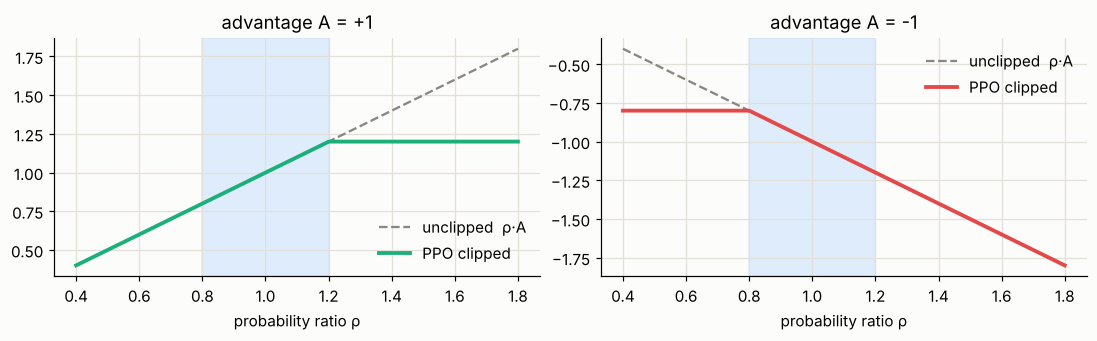

In [11]:
rr = np.linspace(0.4, 1.8, 300); eps = 0.2
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, A, col in ((axs[0], 1.0, AQUA), (axs[1], -1.0, RED)):
    ax.plot(rr, rr * A, "--", color="#898781", label="unclipped  ρ·A")
    ax.plot(rr, np.minimum(rr * A, np.clip(rr, 1 - eps, 1 + eps) * A), color=col, lw=2.5, label="PPO clipped")
    ax.axvspan(1 - eps, 1 + eps, color="#cde2fb", alpha=0.6)
    ax.set_title(f"advantage A = {A:+.0f}"); ax.set_xlabel("probability ratio ρ"); ax.legend()
plt.tight_layout(); plt.show()

When $A>0$ the objective stops rewarding increases of $\rho$ beyond $1+\epsilon$; when $A<0$ it stops
rewarding decreases below $1-\epsilon$. Because of the $\min$, the clip only ever removes *optimism* —
moves that make the policy look better are capped, moves that make it look worse are not.

## 7. PPO on the planar quadrotor

Implementation details that matter more than they look (Huang et al., 2022, list 37 of them):
16 parallel quadrotors × 256 steps per batch, GAE with $\lambda = 0.95$, 10 epochs of mini-batch 1024,
advantage normalisation per mini-batch, gradient-norm clipping at 0.5, a linearly decaying learning rate,
a state-independent log standard deviation, and a near-zero initial output layer so that the first
policy commands hover. The same time-out bootstrap as in §5 appears in the GAE loop.

In [12]:
class ActorCritic(nn.Module):
    def __init__(self, h=64):
        super().__init__()
        self.mu = mlp(OBS_DIM, ACT_DIM, h)
        self.v = mlp(OBS_DIM, 1, h)
        self.log_std = nn.Parameter(torch.full((ACT_DIM,), -0.5))
        with torch.no_grad():
            self.mu[-1].weight.mul_(0.01); self.mu[-1].bias.zero_()

    def dist(self, o):
        return torch.distributions.Normal(self.mu(o), self.log_std.exp())


def train_ppo(total_steps=1_500_000, n_envs=16, n_steps=256, seed=0, randomize=False,
              gamma=0.99, lam=0.95, clip=0.2, epochs=10, mb=1024, lr=3e-4,
              eval_every=100_000, eval_params=None, verbose=False):
    torch.manual_seed(seed)
    ac = ActorCritic(); opt = torch.optim.Adam(ac.parameters(), lr=lr, eps=1e-5)
    env = PlanarQuad(n_envs, seed=seed, randomize=randomize); o = env.reset()
    n_upd = total_steps // (n_envs * n_steps)
    curve, steps, t0 = [], 0, time.time()
    clipfrac_log, kl_log = [], []
    B = n_envs * n_steps
    for it in range(n_upd):
        for g in opt.param_groups:
            g["lr"] = lr * (1 - it / n_upd)
        O = np.zeros((n_steps, n_envs, OBS_DIM), np.float32); A = np.zeros((n_steps, n_envs, ACT_DIM), np.float32)
        LP = np.zeros((n_steps, n_envs), np.float32); R = np.zeros_like(LP); D = np.zeros_like(LP)
        V = np.zeros_like(LP); VN = np.zeros_like(LP)
        for t in range(n_steps):
            with torch.no_grad():
                ot = torch.as_tensor(o); d = ac.dist(ot); a = d.sample()
                lp = d.log_prob(a).sum(1); v = ac.v(ot).squeeze(1)
            o2, r, crash, trunc, info = env.step(a.numpy())
            with torch.no_grad():                               # bootstrap through time-outs
                vfin = ac.v(torch.as_tensor(info["final_obs"])).squeeze(1).numpy()
            O[t], A[t], LP[t], R[t], V[t] = o, a.numpy(), lp.numpy(), 0.1 * r, v.numpy()
            D[t] = (crash | trunc)
            VN[t] = np.where(trunc, vfin, 0.0)                  # value after a time-out
            o = o2
        steps += B
        with torch.no_grad():
            v_last = ac.v(torch.as_tensor(o)).squeeze(1).numpy()
        adv = np.zeros_like(R); gae = 0.0
        for t in reversed(range(n_steps)):
            v_next = v_last if t == n_steps - 1 else V[t + 1]
            v_next = np.where(D[t] > 0, VN[t], v_next)
            nonterm_gae = 1.0 - D[t]
            delta = R[t] + gamma * v_next - V[t]
            gae = delta + gamma * lam * nonterm_gae * gae
            adv[t] = gae
        ret = adv + V
        Ot, At, LPt = (torch.as_tensor(x.reshape(B, -1)) for x in (O, A, LP))
        LPt = LPt.squeeze(1); ADV = torch.as_tensor(adv.reshape(B)); RET = torch.as_tensor(ret.reshape(B))
        cf, kls = [], []
        for ep in range(epochs):
            perm = torch.randperm(B)
            for s in range(0, B, mb):
                j = perm[s:s + mb]
                d = ac.dist(Ot[j]); lp = d.log_prob(At[j]).sum(1)
                ratio = (lp - LPt[j]).exp()
                a_ = ADV[j]; a_ = (a_ - a_.mean()) / (a_.std() + 1e-8)
                pl = -torch.min(ratio * a_, ratio.clamp(1 - clip, 1 + clip) * a_).mean()
                vl = F.mse_loss(ac.v(Ot[j]).squeeze(1), RET[j])
                ent = d.entropy().sum(1).mean()
                loss = pl + 0.5 * vl - 0.0 * ent
                opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(ac.parameters(), 0.5); opt.step()
                with torch.no_grad():
                    cf.append(((ratio - 1).abs() > clip).float().mean().item())
                    kls.append((LPt[j] - lp).mean().item())
        clipfrac_log.append(np.mean(cf)); kl_log.append(np.mean(kls))
        if steps % eval_every < B or it == n_upd - 1:
            m = rollout(ppo_policy(ac), n=100, params=eval_params)
            curve.append((steps, m["ret"], m["success"]))
            if verbose:
                print(steps, round(m["ret"], 1), m["success"], round(ac.log_std.exp().mean().item(), 3),
                      round(np.mean(cf), 3), round(time.time() - t0, 1))
    return ac, np.array(curve), time.time() - t0, np.array(clipfrac_log), np.array(kl_log)


def ppo_policy(ac):
    def pi(ob):
        with torch.no_grad():
            return ac.mu(torch.as_tensor(ob)).numpy()
    return pi

In [13]:
ac_ppo, ppo_curve, ppo_secs, clipfrac, approx_kl = train_ppo(total_steps=800_000, seed=0, eval_every=20_480)
m_ppo = rollout(ppo_policy(ac_ppo))
print(f"PPO trained in {ppo_secs:.0f} s, {sum(p.numel() for p in ac_ppo.parameters())} parameters (actor + critic)")
print({k: round(v, 4) for k, v in m_ppo.items()})
print(f"mean clip fraction {clipfrac.mean():.3f}, max |approx KL| {np.abs(approx_kl).max():.4f}, "
      f"final action std {ac_ppo.log_std.exp().mean().item():.3f}")

PPO trained in 59 s, 9797 parameters (actor + critic)
{'ret': 225.8407, 'success': 1.0, 'crash': 0.0, 'final_err': 0.0015, 'chatter': 0.0088}
mean clip fraction 0.030, max |approx KL| 0.0141, final action std 0.255


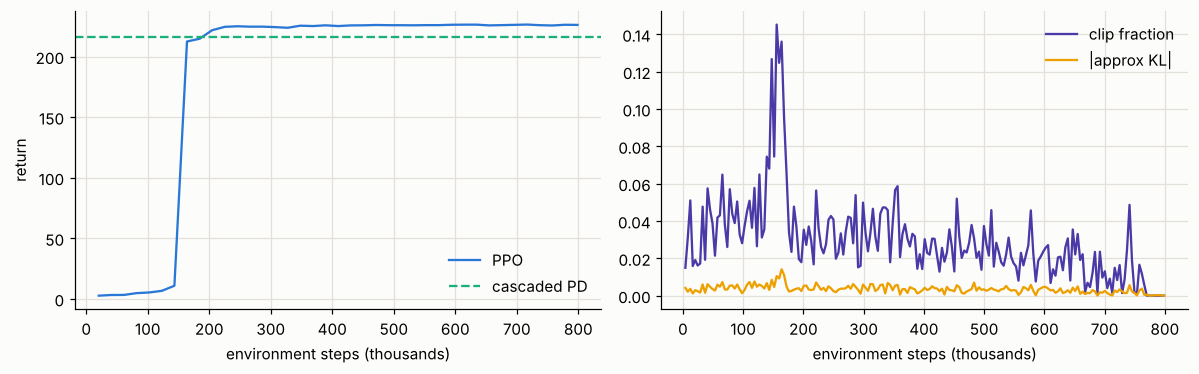

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
axs[0].plot(ppo_curve[:, 0] / 1e3, ppo_curve[:, 1], color=BLUE, label="PPO")
axs[0].axhline(rollout(pd_controller)["ret"], color=AQUA, ls="--", label="cascaded PD")
axs[0].set_xlabel("environment steps (thousands)"); axs[0].set_ylabel("return"); axs[0].legend()
xs = np.arange(1, len(clipfrac) + 1) * 4096 / 1e3
axs[1].plot(xs, clipfrac, color=VIOLET, label="clip fraction"); axs[1].plot(xs, np.abs(approx_kl), color=YELLOW, label="|approx KL|")
axs[1].set_xlabel("environment steps (thousands)"); axs[1].legend()
plt.tight_layout(); plt.show()

PPO reaches ≥ 95 % success after 163,840 environment steps and finishes at return 225.8
(PD: 215.8), 100 % success, median final error 0.1 cm, in about 64 s of CPU time.
The clip fraction — the share of samples whose ratio left $[0.8, 1.2]$ — averages 0.030: the
optimiser is pushing against the clip only occasionally, which is the healthy regime. A clip fraction
stuck above ~0.3, or a KL that spikes, means the learning rate or epoch count is too aggressive.

**Is PPO "better than PD"?** On *this reward*, yes — but the PD gains were hand-picked, not optimised
for this reward. The fair conclusion is "RL matches a competent classical design without being given
the model"; the classical controller still wins on analysability and guarantees.

## 8. Head to head: one difficult start, three controllers

Start 1 m to the left, 0.6 m low, tilted 0.3 rad, and compare the path and the rotor command.

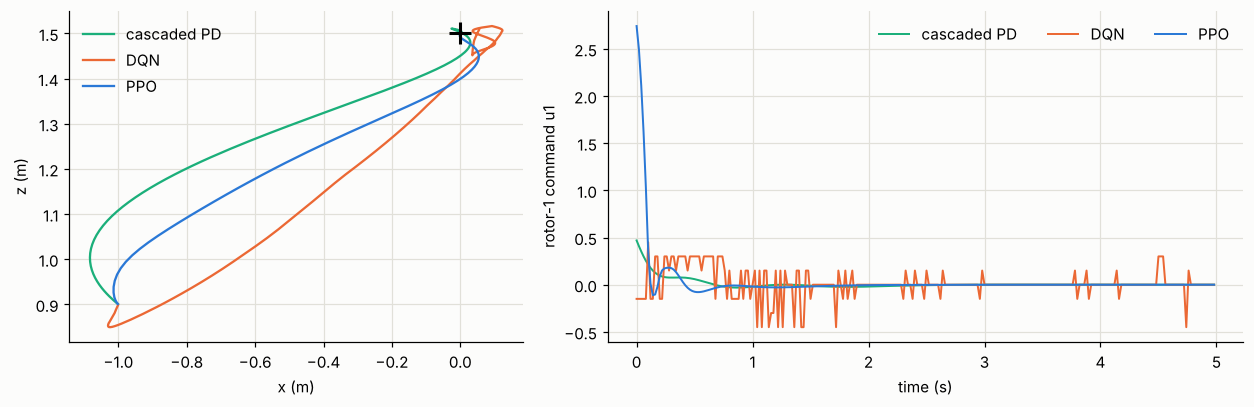

controller     return  success  crash  final err (m)  chatter
cascaded PD     215.8    1.000  0.000         0.0004   0.0013
DQN             204.0    0.980  0.005         0.0696   0.1312
PPO             225.8    1.000  0.000         0.0015   0.0088


In [15]:
s0 = np.array([[-1.0, PlanarQuad.Z_T - 0.6, 0.3, 0.0, 0.0, 0.0]])
pols = {"cascaded PD": (pd_controller, AQUA), "DQN": (dqn_policy(q_dqn), ORANGE), "PPO": (ppo_policy(ac_ppo), BLUE)}
fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.8), gridspec_kw=dict(width_ratios=[1, 1.4]))
t = np.arange(250) * PlanarQuad.DT
for name, (pol, col) in pols.items():
    out = rollout(pol, n=1, init=s0, record=True)
    axs[0].plot(out["traj"][:, 0, 0], out["traj"][:, 0, 1], color=col, label=name)
    axs[1].plot(t, out["u"][:, 0, 0], color=col, lw=1.3, label=name)
axs[0].plot(0, PlanarQuad.Z_T, "k+", ms=14, mew=2); axs[0].set_xlabel("x (m)"); axs[0].set_ylabel("z (m)"); axs[0].legend()
axs[1].set_xlabel("time (s)"); axs[1].set_ylabel("rotor-1 command u1"); axs[1].legend(ncol=3)
plt.tight_layout(); plt.show()

print(f"{'controller':12s} {'return':>8s} {'success':>8s} {'crash':>6s} {'final err (m)':>14s} {'chatter':>8s}")
for name, m in (("cascaded PD", rollout(pd_controller)), ("DQN", m_dqn), ("PPO", m_ppo)):
    print(f"{name:12s} {m['ret']:8.1f} {m['success']:8.3f} {m['crash']:6.3f} {m['final_err']:14.4f} {m['chatter']:8.4f}")

All three reach the target, but look at the right panel. DQN's command jumps between its three levels
for the whole flight — chatter 0.131, about 15× PPO's 0.009. On hardware that is heat in the
ESCs, audible motor noise and excitation of frame modes. **The action space is a modelling choice**:
discretise only when the actuator really is discrete (a gripper open/close, a gear), not because the
algorithm wants it.

## 9. Off-policy actor-critic: SAC

PPO throws each batch away after 10 epochs because its gradient is only valid for the policy that
collected the data (**on-policy**). **Soft actor-critic** (Haarnoja et al., 2018) is off-policy, like DQN,
but with a continuous actor. It keeps a replay buffer, learns twin Q-networks (taking the minimum of the
two to fight over-estimation), and maximises reward *plus entropy*,

$$J(\pi) = \mathbb E\Big[\sum_t \gamma^t\big(r_t + \alpha\,\mathcal H(\pi(\cdot\mid s_t))\big)\Big],$$

with the temperature $\alpha$ tuned automatically towards a target entropy. The actor is a tanh-squashed
Gaussian, so actions stay in $[-1,1]$; the log-probability needs the change-of-variables correction.
SAC does one gradient update per environment step, which is where both its sample efficiency and its
compute cost come from.

In [16]:
class SquashedActor(nn.Module):
    def __init__(self, h=64):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(OBS_DIM, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU())
        self.mu = nn.Linear(h, ACT_DIM); self.ls = nn.Linear(h, ACT_DIM)

    def forward(self, o, deterministic=False):
        h = self.body(o); mu = self.mu(h); ls = self.ls(h).clamp(-5, 1)
        if deterministic:
            return torch.tanh(mu), None
        d = torch.distributions.Normal(mu, ls.exp()); x = d.rsample(); a = torch.tanh(x)
        lp = d.log_prob(x).sum(1) - (2 * (np.log(2) - x - F.softplus(-2 * x))).sum(1)
        return a, lp


def qnet(h=128):
    return nn.Sequential(nn.Linear(OBS_DIM + ACT_DIM, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU(), nn.Linear(h, 1))


def train_sac(total_steps=60_000, n_envs=4, seed=0, batch=256, lr=1e-3, gamma=0.99, tau=0.01,
              start=2_000, utd=1.0, eval_every=5_000, verbose=False):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    actor = SquashedActor(); q1, q2, q1t, q2t = qnet(), qnet(), qnet(), qnet()
    q1t.load_state_dict(q1.state_dict()); q2t.load_state_dict(q2.state_dict())
    oa = torch.optim.Adam(actor.parameters(), lr=lr)
    oq = torch.optim.Adam(list(q1.parameters()) + list(q2.parameters()), lr=lr)
    log_alpha = torch.zeros(1, requires_grad=True); oal = torch.optim.Adam([log_alpha], lr=lr)
    target_ent = -float(ACT_DIM)
    env = PlanarQuad(n_envs, seed=seed); o = env.reset()
    cap = total_steps
    BO = np.zeros((cap, OBS_DIM), np.float32); BO2 = np.zeros_like(BO)
    BA = np.zeros((cap, ACT_DIM), np.float32); BR = np.zeros(cap, np.float32); BD = np.zeros(cap, np.float32)
    n, steps, curve, t0, debt = 0, 0, [], time.time(), 0.0
    pol = lambda ob: actor(torch.as_tensor(ob), True)[0].detach().numpy()
    while steps < total_steps:
        if steps < start:
            a = rng.uniform(-1, 1, (n_envs, ACT_DIM)).astype(np.float32)
        else:
            with torch.no_grad():
                a = actor(torch.as_tensor(o))[0].numpy()
        o2, r, crash, trunc, info = env.step(a)
        nxt = np.where((crash | trunc)[:, None], info["final_obs"], o2)
        j = slice(n, n + n_envs)
        BO[j], BA[j], BR[j], BO2[j], BD[j] = o, a, 0.1 * r, nxt, crash
        n += n_envs; steps += n_envs; o = o2
        if steps >= start:
            debt += utd * n_envs
            while debt >= 1:
                debt -= 1
                k = rng.integers(0, n, batch)
                ob, ab, rb, ob2, db = (torch.as_tensor(x[k]) for x in (BO, BA, BR, BO2, BD))
                alpha = log_alpha.exp().detach()
                with torch.no_grad():
                    a2, lp2 = actor(ob2)
                    x2 = torch.cat([ob2, a2], 1)
                    y = rb + gamma * (1 - db) * (torch.min(q1t(x2), q2t(x2)).squeeze(1) - alpha * lp2)
                x = torch.cat([ob, ab], 1)
                lq = F.mse_loss(q1(x).squeeze(1), y) + F.mse_loss(q2(x).squeeze(1), y)
                oq.zero_grad(); lq.backward(); oq.step()
                an, lp = actor(ob); xn = torch.cat([ob, an], 1)
                la = (alpha * lp - torch.min(q1(xn), q2(xn)).squeeze(1)).mean()
                oa.zero_grad(); la.backward(); oa.step()
                lal = -(log_alpha * (lp.detach() + target_ent)).mean()
                oal.zero_grad(); lal.backward(); oal.step()
                with torch.no_grad():
                    for net, tgt in ((q1, q1t), (q2, q2t)):
                        for p, pt in zip(net.parameters(), tgt.parameters()):
                            pt.mul_(1 - tau).add_(tau * p)
        if steps % eval_every < n_envs:
            m = rollout(pol, n=100)
            curve.append((steps, m["ret"], m["success"]))
            if verbose:
                print(steps, round(m["ret"], 1), m["success"], round(log_alpha.exp().item(), 4), round(time.time() - t0, 1))
    return actor, np.array(curve), time.time() - t0


def sac_policy(actor):
    def pi(ob):
        with torch.no_grad():
            return actor(torch.as_tensor(ob), True)[0].numpy()
    return pi

In [17]:
actor_sac, sac_curve, sac_secs = train_sac(total_steps=20_000, seed=0, eval_every=2_000)
m_sac = rollout(sac_policy(actor_sac))
print(f"SAC: {sac_secs:.0f} s for 20 000 environment steps")
print({k: round(v, 4) for k, v in m_sac.items()})

def first_reach(curve, thr=190.0):
    k = np.flatnonzero(curve[:, 1] >= thr)
    return int(curve[k[0], 0]) if len(k) else None

print(f"{'':5s} {'steps to return 190':>20s} {'CPU µs / env step':>18s}")
for name, curve, secs, n in (("SAC", sac_curve, sac_secs, 20_000), ("DQN", dqn_curve, dqn_secs, 240_000),
                             ("PPO", ppo_curve, ppo_secs, int(ppo_curve[-1, 0]))):
    print(f"{name:5s} {str(first_reach(curve)):>20s} {1e6 * secs / n:18.0f}")

SAC: 123 s for 20 000 environment steps
{'ret': 197.2955, 'success': 0.0, 'crash': 0.0, 'final_err': 0.1395, 'chatter': 0.0108}
       steps to return 190  CPU µs / env step
SAC                  18000               6139
DQN                 180000                279
PPO                 163840                 74


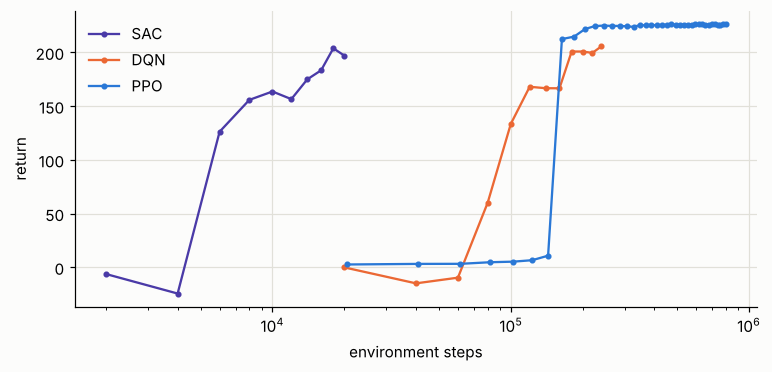

In [18]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for name, curve, col in (("SAC", sac_curve, VIOLET), ("DQN", dqn_curve, ORANGE), ("PPO", ppo_curve, BLUE)):
    ax.plot(curve[:, 0], curve[:, 1], marker="o", ms=3, color=col, label=name)
ax.set_xscale("log"); ax.set_xlabel("environment steps"); ax.set_ylabel("return"); ax.legend(); plt.show()

SAC passes return 190 after 18,000 environment steps; PPO needs 163,840 and DQN 180,000. But
each SAC step costs about 6599 µs of CPU against 80 µs for PPO, because of the per-step updates
of three networks. The choice therefore depends on **what is expensive**:

| what is scarce | prefer | because |
|---|---|---|
| real-robot time (learning on hardware) | SAC / off-policy | reuses every sample many times |
| wall-clock with a fast, parallel simulator | PPO / on-policy | cheap updates, scales to thousands of envs |
| discrete actuator | DQN family | no actor needed |

SAC's final policy here is good (return 197.3) but sits 14.0 cm from the target, so its strict
success score is 0 %: it has been trained for 40× fewer steps and has not yet removed its
steady-state offset (exercise 4).

## 10. Sim-to-real: domain randomisation

A policy trained on one simulator meets a different quadrotor: a heavier battery, motors with a slower
response, ESC latency. We test the nominal PPO policy on a grid of masses (0.8–1.45 × nominal) and motor
time constants (0–100 ms). Then we retrain PPO with **domain randomisation** (Tobin et al., 2017;
Molchanov et al., 2019): every episode draws mass and inertia from 0.75–1.35 ×, motor strength from
0.80–1.10 × and motor lag from 0–80 ms. The policy cannot tell which quad it is flying, so it must
find one behaviour that works for all of them.

domain-randomised PPO trained in 61 s
nominal quad: nominal-PPO return 225.8 | DR-PPO return 224.1


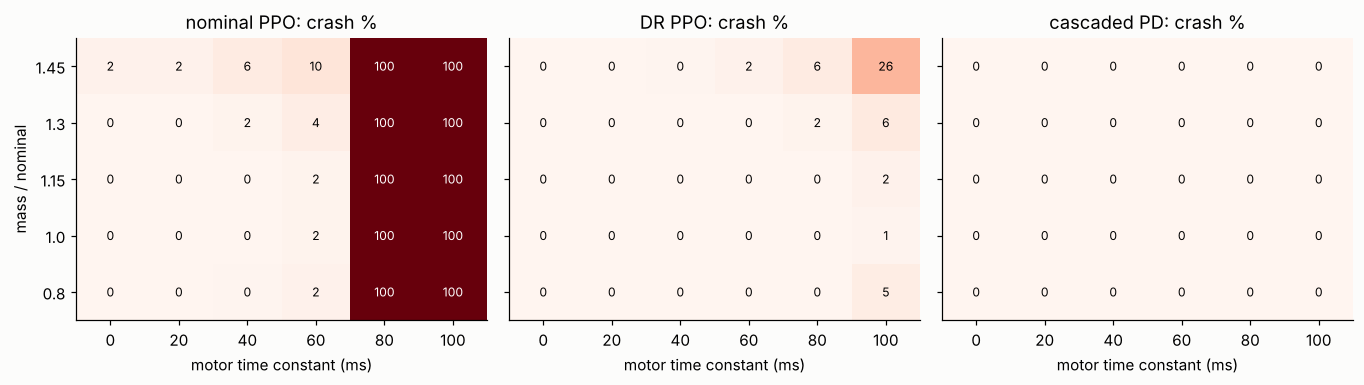

nominal PPO  crash at 80 ms lag: 100.0 %   final error at 1.45x mass, no lag:  12.1 cm   mean crash inside the DR box:  20.6 %
DR PPO       crash at 80 ms lag:   0.0 %   final error at 1.45x mass, no lag:   6.0 cm   mean crash inside the DR box:   0.1 %
cascaded PD  crash at 80 ms lag:   0.0 %   final error at 1.45x mass, no lag: 110.2 cm   mean crash inside the DR box:   0.0 %


In [19]:
ac_dr, dr_curve, dr_secs, _, _ = train_ppo(total_steps=800_000, seed=0, randomize=True, eval_every=20_480)
print(f"domain-randomised PPO trained in {dr_secs:.0f} s")
print("nominal quad: nominal-PPO return", round(rollout(ppo_policy(ac_ppo))["ret"], 1),
      "| DR-PPO return", round(rollout(ppo_policy(ac_dr))["ret"], 1))

MS = np.array([0.80, 1.00, 1.15, 1.30, 1.45]); LAGS = np.array([0.0, 0.02, 0.04, 0.06, 0.08, 0.10])
grids = {}
for name, pol in (("nominal PPO", ppo_policy(ac_ppo)), ("DR PPO", ppo_policy(ac_dr)), ("cascaded PD", pd_controller)):
    crash = np.zeros((len(MS), len(LAGS))); err = np.zeros_like(crash)
    for i, ms in enumerate(MS):
        for j, lg in enumerate(LAGS):
            m = rollout(pol, n=200, params=dict(mass=NOMINAL["mass"] * ms, lag=lg))
            crash[i, j], err[i, j] = m["crash"], m["final_err"]
    grids[name] = (crash, err)

fig, axs = plt.subplots(1, 3, figsize=(12.5, 3.6), sharey=True)
for ax, (name, (crash, err)) in zip(axs, grids.items()):
    ax.imshow(crash, origin="lower", cmap="Reds", vmin=0, vmax=1, aspect="auto")
    for i in range(len(MS)):
        for j in range(len(LAGS)):
            ax.text(j, i, f"{100 * crash[i, j]:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if crash[i, j] > 0.5 else "black")
    ax.set_xticks(range(len(LAGS))); ax.set_xticklabels([f"{1000 * l:.0f}" for l in LAGS])
    ax.set_yticks(range(len(MS))); ax.set_yticklabels(MS); ax.grid(False)
    ax.set_title(f"{name}: crash %"); ax.set_xlabel("motor time constant (ms)")
axs[0].set_ylabel("mass / nominal"); plt.tight_layout(); plt.show()

i100, j80 = 1, 4
for name, (crash, err) in grids.items():
    print(f"{name:12s} crash at 80 ms lag: {100 * crash[i100, j80]:5.1f} %   "
          f"final error at 1.45x mass, no lag: {100 * err[-1, 0]:5.1f} cm   "
          f"mean crash inside the DR box: {100 * crash[:4, :5].mean():5.1f} %")

The nominal policy is excellent on the quad it was trained on and fragile everywhere else: with an
80 ms motor time constant (at nominal mass) it crashes in 100.0 % of episodes. It learned high-gain
feedback that is only stable without actuator delay. The randomised policy crashes in 0.0 % at the
same point, and its sag under a 1.45 × mass drops from 12.1 cm to 6.0 cm. Averaged over the randomised range (mass ≤ 1.30 ×, lag ≤ 80 ms) the crash rate falls from 20.6 % to 0.1 %. The price on the
nominal quad is small: return 224.1 against 225.8.

Two caveats worth saying out loud:

* **Randomisation covers only what you randomise.** At 100 ms lag and 1.45 × mass — outside the training
  range — the DR policy still crashes 26 % of the time.
* The fixed-gain PD controller never crashes on this grid (0.0 % at 80 ms) because its gains are
  modest, but it sags 110.2 cm under the heavy battery because it has no integral action. Robustness
  and precision are different properties; measure both.

## 11. Recent advances, and where quadrotors fit

| year | development | why it matters for robots |
|---|---|---|
| 2015 | DQN (Mnih et al., *Nature*) | deep function approximation made stable |
| 2015 / 2017 | TRPO, PPO (Schulman et al.) | trust-region policy optimisation; PPO is the default for sim-trained locomotion and flight |
| 2017 | Hwangbo et al., *RA-L* | a neural policy stabilises a real quadrotor, even from a hand throw |
| 2018 | SAC (Haarnoja et al.) | off-policy, sample-efficient continuous control; used for learning on hardware |
| 2019 | Molchanov et al., IROS | one policy, trained with randomisation, transfers to several different quadrotors |
| 2020–23 | Dreamer → DreamerV3 (Hafner et al.) | learn a **world model** and train the policy inside it |
| 2021 | Rudin et al., CoRL | thousands of parallel GPU simulations: a walking policy in minutes |
| 2022 | RLHF / InstructGPT (Ouyang et al.) | PPO used to fine-tune language models from human preferences |
| 2023 | Swift (Kaufmann et al., *Nature*) | deep-RL drone racer beats human world champions on a real track |
| 2023 | Song et al., *Science Robotics* | RL vs optimal control for racing: RL wins by optimising the true task objective |
| 2025 | DeepSeek-R1 (GRPO) | RL with verifiable rewards trains reasoning in LLMs — PPO's descendants, without a critic |

The common thread for robotics: **train in simulation at scale, randomise what you cannot model, and
fine-tune or correct with residual models from real data.** Swift, for example, learned its policy in
simulation and corrected the simulator with data-driven residual models of perception and dynamics
collected on the real track.

## 12. Protocol — what to remember

1. **Write the MDP before the code.** State must be Markov; actions must match the actuator; know which
   episode endings are terminal and which are truncations.
2. **Build a classical baseline first** (PD, LQR, MPC). It tells you what "good" is and catches broken
   environments.
3. **Reward shaping is controller design.** Every term ($|\theta|$, $|\Delta u|$, alive bonus) is a gain you
   are choosing; change one and the behaviour changes.
4. **Discrete actions on a continuous actuator cause chatter.** Use PPO/SAC for thrust and torque.
5. **Bootstrap through time limits.** `terminated` and `truncated` are different.
6. **Watch the diagnostics**, not only the return: clip fraction and KL for PPO, Q-values and α for SAC,
   crash rate and command smoothness for the robot.
7. **Pick on-policy vs off-policy by what is expensive**: simulator throughput favours PPO, real-robot
   time favours SAC.
8. **Randomise the simulator wider than your uncertainty**, and evaluate outside the training range.
9. **Report robotics metrics** — crash rate, steady-state error, chatter, robustness grid — next to return.

## 13. Exercises

1. **Discount and horizon.** Re-run value iteration with $\gamma$ = 0.8 and 0.995. How does the switching
   curve change, and why? Relate $1/(1-\gamma)$ to a time horizon at a 0.1 s step.
2. **The time-out bug.** Train DQN with `bootstrap_timeout=False`. Compare return and final error, and
   plot $\max_a Q$ against time-in-episode for both agents.
3. **A finer DQN action set.** Use 5 × 5 instead of 3 × 3 actions. Does chatter fall? What happens to
   training time and success? Where does this approach break down for a 4-rotor vehicle?
4. **Finish SAC.** Train SAC for 60 000 steps and compare final error with PPO. Then try `utd=2`. Plot
   return against wall-clock seconds rather than steps — does the ranking change?
5. **Reward shaping.** Remove the $0.05\|\Delta u\|$ smoothness term from the reward and retrain PPO.
   Measure chatter. Then double it. What does the policy trade away?
6. **Integral action.** Append the running integral of $e_z$ (clipped) to the observation. Does the DR
   policy's sag under a 1.45 × mass disappear? Explain in control terms.
7. **Wind gusts.** Add a random horizontal force (a slowly varying Ornstein–Uhlenbeck process) to
   `PlanarQuad.step`. Train with and without gusts and evaluate both in gusty air.
8. **Way-point flight.** Put a random target in the observation instead of a fixed hover point and train
   PPO to fly to it. What must change in the reward and the termination rules?

## 14. References

* R. S. Sutton and A. G. Barto, *Reinforcement Learning: An Introduction*, 2nd ed., MIT Press, 2018.
* V. Mnih et al., "Human-level control through deep reinforcement learning," *Nature* 518, 529–533, 2015.
* J. Schulman, S. Levine, P. Moritz, M. Jordan, P. Abbeel, "Trust region policy optimization," ICML 2015.
* J. Schulman, P. Moritz, S. Levine, M. Jordan, P. Abbeel, "High-dimensional continuous control using
  generalized advantage estimation," ICLR 2016.
* J. Schulman, F. Wolski, P. Dhariwal, A. Radford, O. Klimov, "Proximal policy optimization algorithms,"
  arXiv:1707.06347, 2017.
* T. Haarnoja, A. Zhou, P. Abbeel, S. Levine, "Soft actor-critic: off-policy maximum entropy deep
  reinforcement learning with a stochastic actor," ICML 2018.
* H. van Hasselt, A. Guez, D. Silver, "Deep reinforcement learning with double Q-learning," AAAI 2016.
* J. Hwangbo, I. Sa, R. Siegwart, M. Hutter, "Control of a quadrotor with reinforcement learning,"
  *IEEE Robotics and Automation Letters* 2(4), 2017.
* J. Tobin et al., "Domain randomization for transferring deep neural networks from simulation to the
  real world," IROS 2017.
* A. Molchanov et al., "Sim-to-(multi)-real: transfer of low-level robust control policies to multiple
  quadrotors," IROS 2019.
* N. Rudin, D. Hoeller, P. Reist, M. Hutter, "Learning to walk in minutes using massively parallel deep
  reinforcement learning," CoRL 2021.
* D. Hafner, J. Pasukonis, J. Ba, T. Lillicrap, "Mastering diverse domains through world models"
  (DreamerV3), arXiv:2301.04104, 2023.
* E. Kaufmann et al., "Champion-level drone racing using deep reinforcement learning," *Nature* 620,
  982–987, 2023.
* Y. Song, A. Romero, M. Müller, V. Koltun, D. Scaramuzza, "Reaching the limit in autonomous racing:
  optimal control versus reinforcement learning," *Science Robotics* 8(82), 2023.
* S. Huang et al., "The 37 implementation details of proximal policy optimization," ICLR Blog Track, 2022.
* L. Ouyang et al., "Training language models to follow instructions with human feedback," NeurIPS 2022.
* DeepSeek-AI, "DeepSeek-R1: incentivizing reasoning capability in LLMs via reinforcement learning,"
  arXiv:2501.12948, 2025.
* Gymnasium documentation — `terminated` vs `truncated`: https://gymnasium.farama.org/ ;
  Stable-Baselines3 documentation: https://stable-baselines3.readthedocs.io/

Generated by Claude and customized by

<div align="center">
<img src="https://raw.githubusercontent.com/dewdotninja/sharing-github/refs/heads/master/dewninja_logo50.jpg" alt="dewninja"/>
</div>
<div align="center">dew.ninja 2026</div>